# MX017 · MX024 · MX080 — ทบทวน Auto-Calibration จากข้อมูลรายวินาที

## tl;dr
ผลและกราฟด้านล่างมาจาก ZIP 5 ส่วนใน Downloads ที่ส่งเมื่อ 1 ตุลาคม 2026 ไม่ใช่ข้อมูลจำลอง และไม่ใช่ผลจาก Active Profile รุ่นใหม่

คำถามสำคัญ: baseline ต่างกันแค่ไหน, ช่วง ON นิ่งทันทีหรือไม่, การใช้ประวัติยาวขึ้นช่วยหรือกลบการเปลี่ยนระดับ, และควรปรับ lifecycle อย่างไร

**รอบนี้เป็นการวิเคราะห์และเสนอแนวทางเท่านั้น:** ไม่เขียน MySQL ไม่เปลี่ยน Profile/threshold/worker และไม่ deploy Server

### สรุปจากข้อมูลที่อ่านครบแล้ว
- **MX017 / MX024 / MX080**, เครื่องละ93ไฟล์รายวัน รวม **23,347,480 แถว** ตั้งแต่1Julถึง1Oct2026 (1Octเป็นวันไม่เต็ม); ไม่ใช้Static
- **2,036,991 qualified Cold module-minutes**. คำว่าqualifiedยังไม่ใช่normal label
- **81.23%** ของqualifiedminutesไม่ทราบonsetที่เชื่อถือได้จากobserved Run/control boundary: อย่าเริ่มtimerใหม่ที่ต้นไฟล์หรือหลังsourcegap
- Module7ข้อมูลไม่พอทุกเครื่อง: MX017=0, MX024=102, MX080=36 qualifiedminutes; จึงยังไม่มีbasisสำหรับsteadyprofileของM7
- MX080/M6 daily Hp_2nd median: 3–6Sepประมาณ190psi, 7–8Sepประมาณ332–340psi, 18–21Sepประมาณ298–314psi และปลายSepประมาณ176–180psi. เป็นหลายระดับที่ต้องreviewแยก ไม่ใช่fitรวมแล้วบอกปกติ
- ตัวอย่างcut26Sep: fit7/14วันมีHp_2nd scale97.79/87.34psiและflags0/3,420minutes; ค่าเตือนที่ลดลงจึงไม่ใช่หลักฐานว่าแม่นขึ้น. ยังต้องตรวจdrift/quarantine/shadow/approvalทุกgate

**ข้อเสนอหลัก:** ทำphase-aware + stable-reference/epoch-aware calibration, ใช้ประวัติยาวเป็นevidence bank, freezebaselineเดิมระหว่างshiftreview. ยังไม่ต้องเปลี่ยนไปLSTMหรือretrainโมเดลใหม่

## Context & Methods
### Key Assumptions
- Timestamp ได้จากวันในชื่อไฟล์ + Time ในบรรทัด; log ไม่มี timezone offset จึงรักษานาฬิกาต้นทาง ไม่อ้างว่าตรวจยืนยัน timezone แล้ว
- Pressure ใช้หน่วยต้นทางที่คาดว่า psi, Temperature คาดว่า °C และ Valve เป็น command count ตาม contract; ไม่ได้มี calibration certificate
- ใช้เฉพาะ daily `.txt` ที่มี 82 columns; **ไม่ใช้ `_Static.txt`** ตามคำขอ
- ไม่มี healthy/fault labels สำหรับทุกช่วง: คำว่า qualified หมายถึงผ่านข้อมูล/สถานะ ไม่ใช่ตรวจยืนยันว่าเครื่องไม่มีปัญหา
- `Status=Run`, `Status_n=On`, `Busy_n=0`, `SV_n=Off`, Valve≥0, numeric finite ทุกวินาทีในนาที
- Minute ต้องมีอย่างน้อย 57 unique seconds, gap≤5s รวมขอบนาที และไม่มี duplicate. Features เป็น mean ของวินาทีที่สังเกตจริง ไม่ fill missing
- ช่วงอายุ Cold ≥20min เป็น **sensitivity slice** ไม่ใช่กฎ settling ที่ fitted แล้ว; onset ไม่ทราบแยกต่างหาก ไม่แต่งเวลาขึ้นมา
- กราฟ startup แสดง raw seconds หลัง observed Run entry, แยกจาก post-manual/control-entry. เก็บ ledger ทุก event แต่ raw plot cacheจำกัด 5 events/module/day/kind, duration≥120s, สูงสุด30min; censoredที่ท้ายวัน
- Correlation ไม่ใช่ causality; daily-median centering ลด level confounding บางส่วน แต่ไม่มี recipe/load/water จึงยังเทียบ context ได้ไม่ครบ

### 1. Setup และการรันใหม่
Notebook ใช้ `support/october_three_machine_calibration.py` เป็น data preparation และ `support/october_calibration_presentation.py` เป็น plotting code ทั้งคู่ตรวจสอบได้

สำหรับ Colab ให้อัปโหลด notebook, สอง scripts และ derived output folder หรือ mount Drive. เปลี่ยน `SOURCE_DIR` เป็น folder ZIP ของคุณ เมื่อต้องการคำนวณจาก raw ใหม่ให้ตั้ง `REBUILD_RAW=True`. การ rebuild ใช้เวลาหลายนาทีและอ่านไฟล์หลาย GB; ค่าเริ่มต้นอ่าน cache ที่มี manifest/hash

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'support').is_dir() and (ROOT / 'notebooks/support').is_dir():
    ROOT = ROOT / 'notebooks'
sys.path.insert(0, str(ROOT / 'support'))
import october_three_machine_calibration as audit
import october_calibration_presentation as visuals
get_ipython().run_line_magic('matplotlib', 'inline')

SOURCE_DIR = Path('C:/Users/Book/Downloads')  # Colab: /content/drive/MyDrive/...
OUTPUT = ROOT / 'outputs/october_three_machine_calibration_v1'
REBUILD_RAW = False
if REBUILD_RAW:
    audit.ingest(SOURCE_DIR, OUTPUT)
    audit.summarize(OUTPUT)
    audit.extract_run_trajectories(SOURCE_DIR, OUTPUT)
manifest = json.loads((OUTPUT/'ingestion_manifest.json').read_text(encoding='utf-8'))
summary = json.loads((OUTPUT/'analysis_summary.json').read_text(encoding='utf-8'))
display(pd.Series(summary, name='Verified analysis scope'))


module_minute_rows                    3214080
raw_present_minutes                   3156896
quality_minutes                       3084896
qualified_cold_minutes                2036991
age20_minutes                          357440
unknown_onset_cold_minutes            1654644
context_count                              24
events                                 167104
causal_experiments                       1059
normal_labels_available                 False
age20_is_sensitivity_not_live_gate       True
active_or_database_changed              False
Name: Verified analysis scope, dtype: object

## Data
### 2. ตรวจที่มาและขอบเขตก่อนตีความ
ZIP ส่วนที่ 2 มี MX080 เดือนกรกฎาคมซ้อนอยู่ จึงต้องอ่าน nested archive ด้วย. ตาราง hash และ inventory ป้องกันการตกหล่น/นับซ้ำ; Staticมีแค่รายชื่อใน inventoryแต่ไม่ถูก parse หรือวิเคราะห์

,day_files,raw_rows,first,last,duplicate_rows,missing_cells,nonmonotonic_steps
machine,,,,,,,
017,93,7772969,2026-07-01 00:00:00,2026-10-01 15:55:01,40617,0,700
024,93,7801416,2026-07-01 00:00:00,2026-10-01 15:45:00,13143,0,220
080,93,7773095,2026-07-01 00:00:00,2026-10-01 15:34:59,4380,0,18


,archive,bytes,sha256
0,HT9046MX-Compressor-Data-20261001T095156Z-1-00...,166818967,40ccc6c69aa29a8f0f6d752531f16f8198b999910ed491...
1,HT9046MX-Compressor-Data-20261001T095156Z-1-00...,264023535,f346a7b3d5e892bfb8e39bae10b7b7d47a59c1e58f0943...
2,HT9046MX-Compressor-Data-20261001T095156Z-1-00...,201127212,3fef794f6a4fc926d44c1bcbfefea11c42047876e23074...
3,HT9046MX-Compressor-Data-20261001T095156Z-1-00...,199491812,e66ecb9f85900c2038681e2a3f16c36e5d335b4f6cfe7d...
4,HT9046MX-Compressor-Data-20261001T095156Z-1-00...,11532209,4e42874692f8a516968af6f2cc269881161680eae3e9b8...


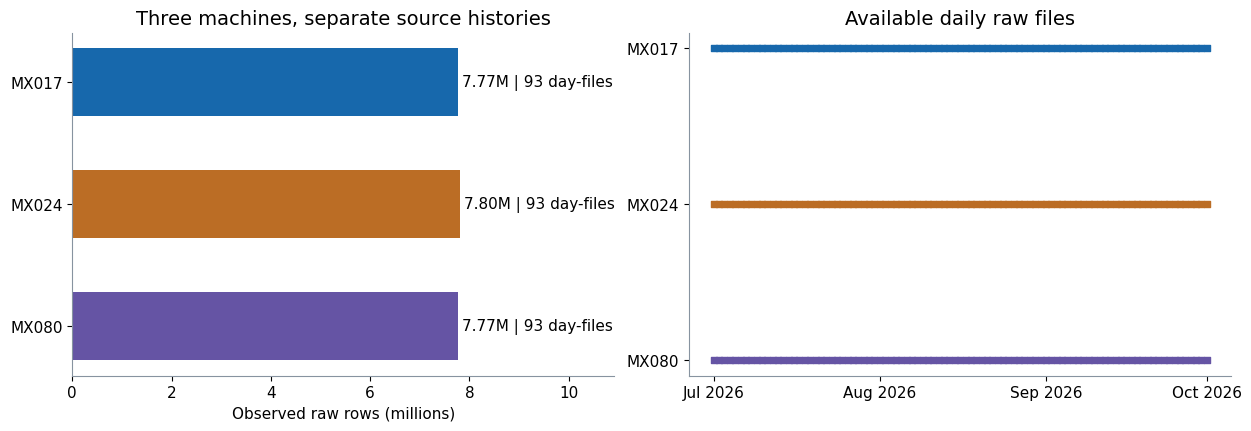

In [2]:
quality = pd.read_csv(OUTPUT/'quality.csv', dtype={'machine':str})
display(quality.groupby('machine').agg(day_files=('date','size'), raw_rows=('rows','sum'),
    first=('first','min'), last=('last','max'), duplicate_rows=('duplicate_seconds','sum'),
    missing_cells=('missing_cells','sum'), nonmonotonic_steps=('nonmonotonic','sum')))
display(pd.DataFrame(manifest['archives'])[['archive','bytes','sha256']])
fig = visuals.coverage(OUTPUT); display(fig); plt.close(fig)


## Results
### 3. Baseline ของแต่ละเครื่อง–แต่ละโมดูล
ดูทั้ง distribution และแนวโน้มตามวัน. เส้นที่นิ่งไม่ได้แปลว่าอยู่ในระดับเดิม: หากกวาดข้อมูลก่อน–หลัง shift มา fitพร้อมกัน baselineและscaleอาจรวมสอง regime. แถบ180–230psiเป็น field reference ของเจ้าของโครงการ ไม่ใช่ safety/normal labelอัตโนมัติ

,machine,module,cold_days,cold_minutes,age20_minutes,unknown_age_minutes,hp2_all_q50,hp2_all_q5,hp2_all_q95
0,017,1,85,105792,5356,99080,194.87,188.54,200.26
1,017,2,86,106124,4874,100110,203.30,201.08,205.98
2,017,3,86,105951,4903,99911,214.96,210.08,218.91
3,017,4,87,106130,4932,100065,197.99,194.92,202.55
4,017,5,85,106046,5016,99919,195.32,192.27,204.20
5,017,6,85,106070,4960,100011,202.92,199.05,207.79
6,017,7,0,0,0,0,NaN,NaN,NaN
7,017,8,84,106027,5030,99916,223.70,205.85,254.75
8,024,1,82,100734,9869,90162,205.27,201.22,209.00
9,024,2,82,100772,12276,87699,201.95,198.51,206.35


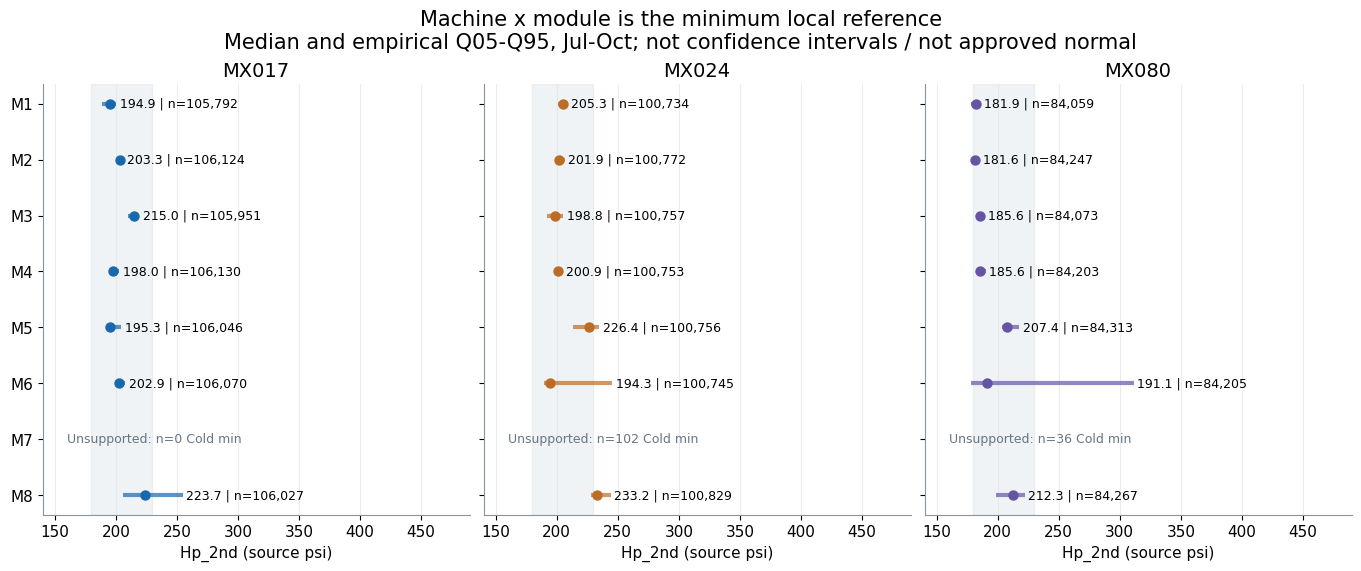

In [3]:
contexts = pd.read_csv(OUTPUT/'context_summary.csv', dtype={'machine':str})
display(contexts[['machine','module','cold_days','cold_minutes','age20_minutes','unknown_age_minutes','hp2_all_q50','hp2_all_q5','hp2_all_q95']].round(2))
fig=visuals.context_baselines(OUTPUT); display(fig); plt.close(fig)


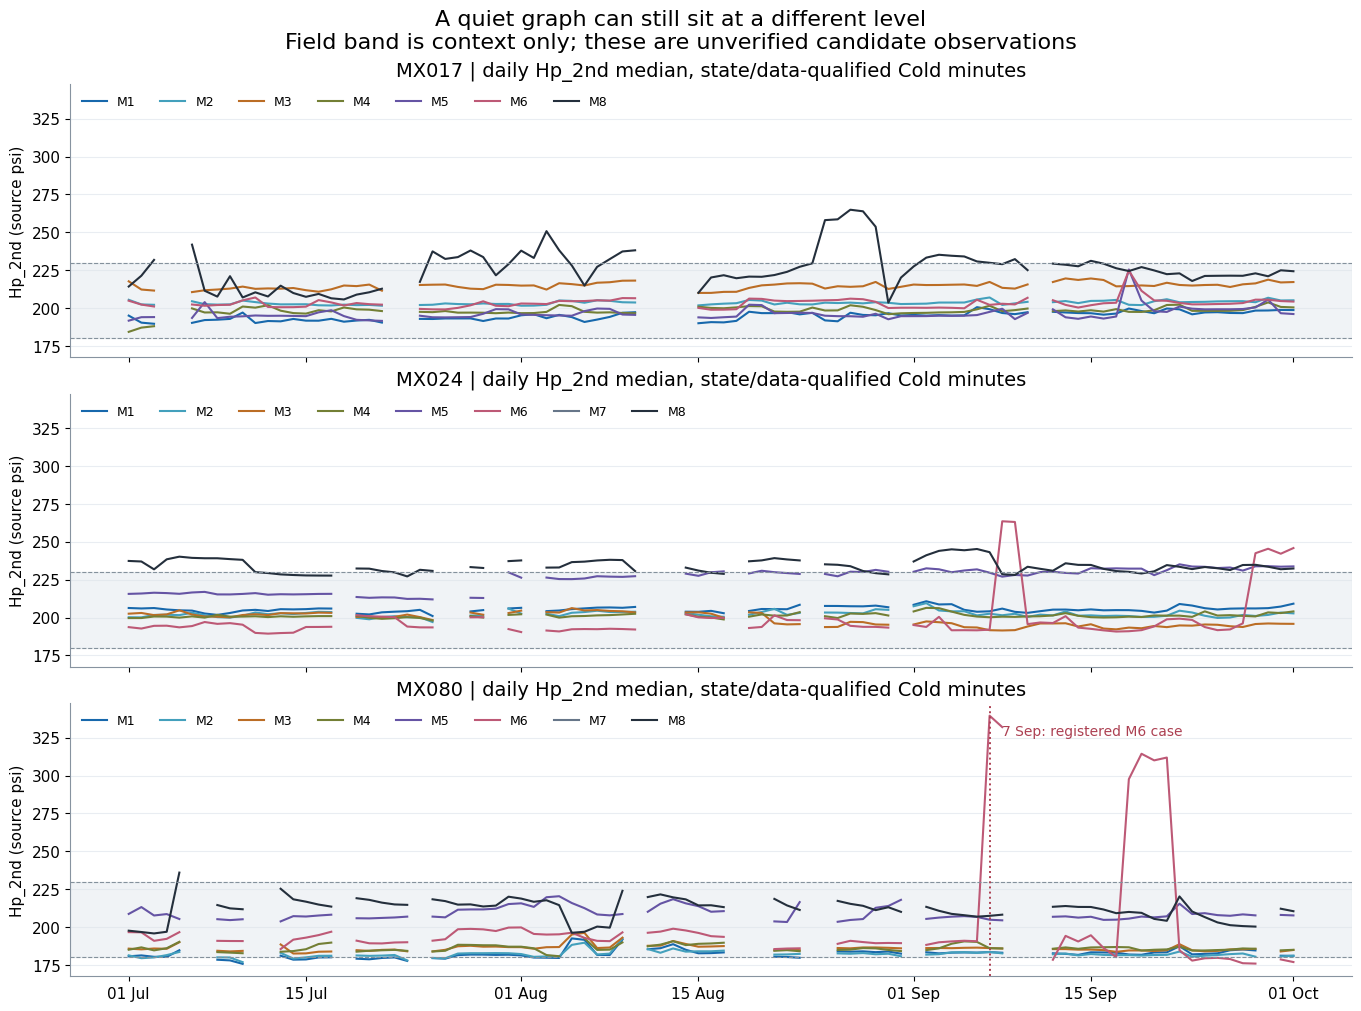

In [4]:
fig=visuals.baseline_timeline(OUTPUT); display(fig); plt.close(fig)


### 4. ความสัมพันธ์เปลี่ยนหรือไม่
Spearman ใช้กับ ranking ไม่บังคับ linear relationship. กราฟนี้หัก median ของแต่ละวันก่อนคำนวณเพื่อลดการเอา level shifts มาสร้าง correlationหลอก. NA คือข้อมูลไม่พอหรือค่าconstant ไม่ใช่ rho=0. อิงทุก state/data-qualified Cold minute; age20 มีผลแยกในตาราง sensitivity จึงไม่ทิ้งนาทีที่ onset ไม่ทราบออกจากภาพหลัก

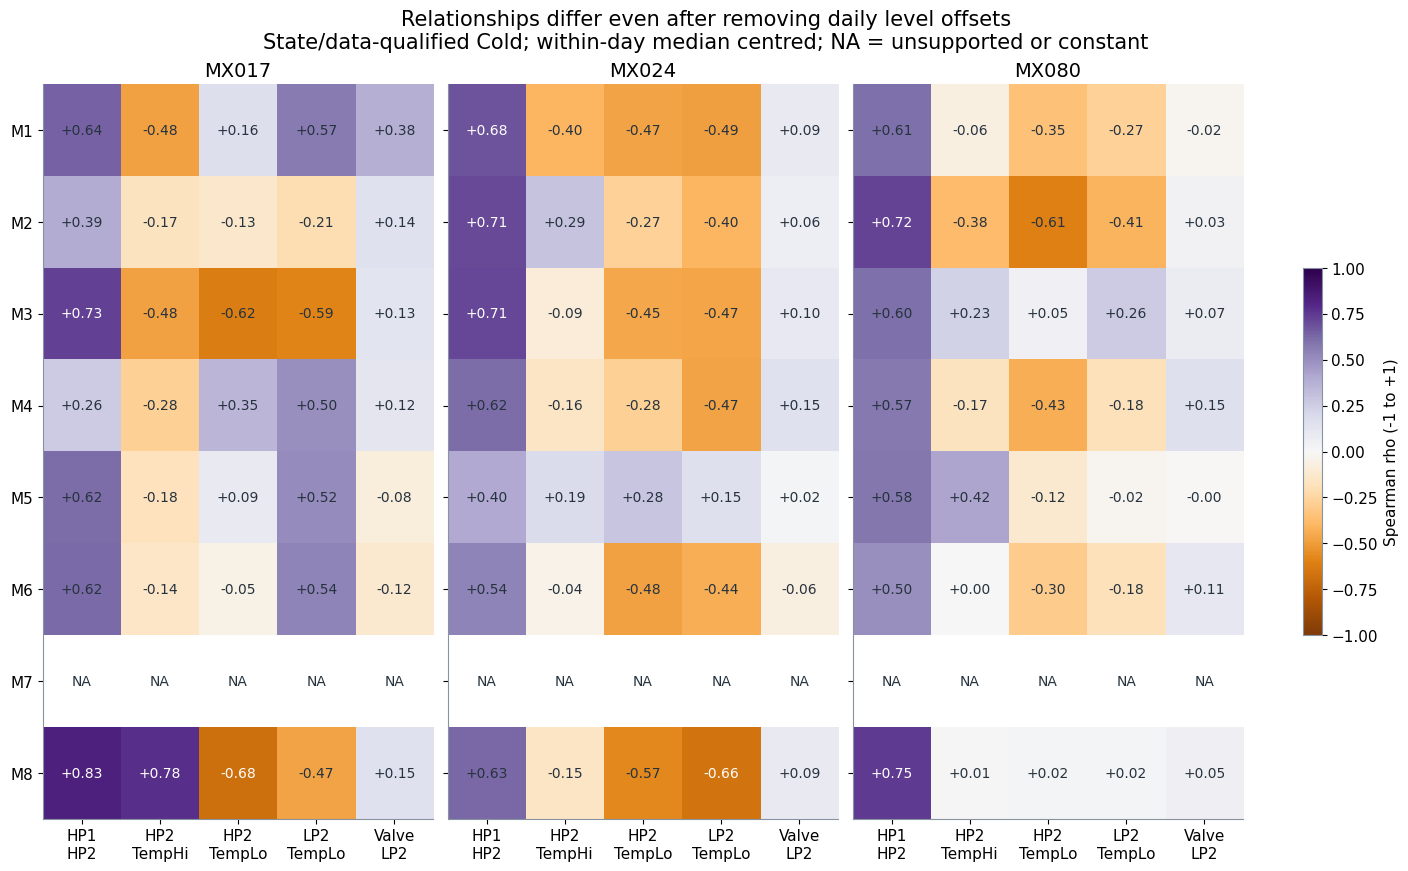

In [5]:
fig=visuals.correlation_chart(OUTPUT); display(fig); plt.close(fig)


### 5. หลายรอบเริ่มเครื่อง บนแกนเวลารายวินาที
`Observed Run start` ต้องเห็น Run หลัง sample non-Run ที่ต่อเนื่อง≤2s. จุดแรกที่ ON อยู่แล้วหรือมี gapเป็น UNKNOWN ไม่ใช่ startที่ยืนยัน. ตัวนับจากCold ledgerนับเฉพาะRunที่เข้าColdพร้อมกัน; **กราฟrawแยกตรวจRun boundaryเอง โดยไม่บังคับColdทันที** และเก็บสถานะที่ตามมาจนRunจบ/30min/ท้ายวัน. ตรวจrawซ้ำเฉพาะวันที่มีmixedRunminute/RunหลังStopminuteหรือCold-ledgerRunentry. กราฟใช้medianข้ามcyclesและQ10–Q90เป็นspread ไม่ใช่CI/healthyenvelope; y scaleแยกต่อpanel. nต้นช่วงไม่รับรองcoverageท้ายช่วง

kind,COLD_CONTROL_ENTRY,OBSERVED_RUN_START,POST_MANUAL,UNKNOWN_GAP_OR_LEFT_CENSORED
machine,,,,
017,411,237,923,116546
024,121,21,385,34466
080,358,91,660,12885


machine
017    45
024     4
080    16
Name: Unique observed Run boundaries, dtype: int64

machine
017    287
024    129
080    134
Name: Raw observed Run entries (Cold qualification not required), dtype: int64

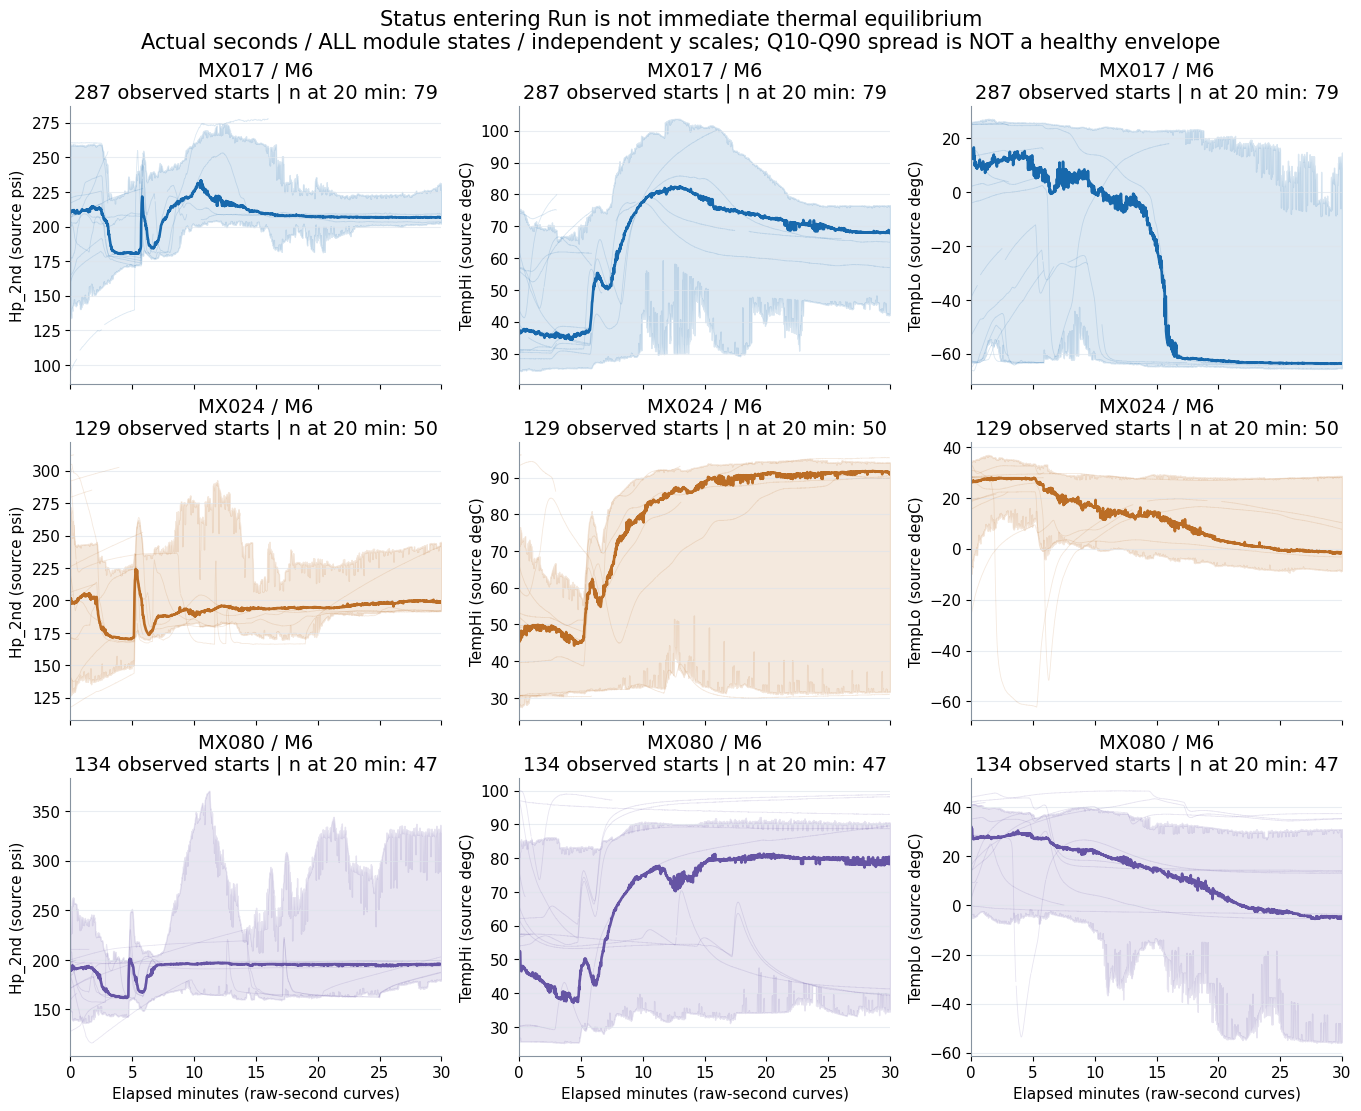

,machine,module,kind,stored_cycles
0,017,6,RAW_OBSERVED_RUN_BOUNDARY,287
1,024,6,RAW_OBSERVED_RUN_BOUNDARY,129
2,080,6,RAW_OBSERVED_RUN_BOUNDARY,134


In [6]:
events=pd.read_csv(OUTPUT/'event_counts.csv',dtype={'machine':str})
display(events.groupby(['machine','kind']).events.sum().unstack(fill_value=0))
event_ledger=pd.read_parquet(OUTPUT/'events.parquet')
display(event_ledger[event_ledger.kind.eq('OBSERVED_RUN_START')].drop_duplicates(['machine','start']).groupby('machine').size().rename('Unique observed Run boundaries'))
display(pd.read_csv(OUTPUT/'raw_run_boundaries.csv',dtype={'machine':str}).groupby('machine').size().rename('Raw observed Run entries (Cold qualification not required)'))
fig=visuals.startup_chart(OUTPUT); display(fig); plt.close(fig)
display(pd.read_csv(OUTPUT/'plotted_start_support.csv',dtype={'machine':str}))


### 6. ทดสอบประวัติย้อนหลัง → shadow 3 วัน
สูตรเหมือน candidateปัจจุบัน (parity testsแยกไว้):

$$m_j=\operatorname{median}(x_j),\quad s_j=\max(1.4826\operatorname{MAD}(x_j),\operatorname{IQR}(x_j)/1.349,f_j)$$
$$z_j=(x_j-m_j)/s_j,\qquad S=\max_j|z_j|$$

Floor $f_j=1$ สำหรับ Valve, $0.1$ สำหรับtagอื่น; screenรอบแรก $S\le8$ แล้วrefit, threshold $q_{0.995}$ ของ retained fit เท่านั้น. Raw flagใช้ $S\ge threshold$; persistent = flagged3นาที qualifiedติดกัน ไม่ข้าม gap.

ใช้weeklycuts1Augเป็นต้นไป, fitก่อนcutย้อนหลังสูงสุด7/14/30/60calendar days → ถัดไป3วัน; actual fit daysอยู่ในCSV (ก่อนSepยังมีrawhistoryไม่ครบ60วัน). Shadowเก็บทุกeligibleminuteเหมือนกัน; age20 sensitivityเปลี่ยนเฉพาะ fit population ไม่ลบstartup flagsออกจากผลทดสอบ. กราฟเปรียบเทียบเฉพาะSeptembercutsที่มีfitทั้ง4lookbacks เพื่อให้shadow denominatorตรงกัน. ไม่มีHPO/การเลือกreleaseจากผลนี้ และknowncaseที่ตรวจแล้วเป็นdiagnosticไม่ใช่freshaccuracytest

shadow_n  raw_flag_pct  \
machine fit_policy                 lookback_days                           
017     current_state_only         7                190965         15.43   
                                   14               238882         11.19   
                                   30               238882         10.49   
                                   60               238882         11.15   
        observed_age20_sensitivity 30               178337         17.19   
                                   60               238882         10.97   
024     current_state_only         7                 84549         13.98   
                                   14               197769         10.94   
                                   30               197769          6.56   
                                   60               197769          7.59   
        observed_age20_sensitivity 30               118555         15.57   
                                   60               175453          9.46   
080     current_state_only         7                 79073         12.79   
                                   14               205531         11.29   
                                   30               205531         12.67   
                                   60               205531         11.37   
        observed_age20_sensitivity 7                 38239         21.22   
                                   14               179984         13.49   
                                   30               205531         10.00   
                                   60               205531          8.60   

                                                  early_n  early_flag_pct  \
machine fit_policy                 lookback_days                            
017     current_state_only         7                 1259           55.68   
                                   14                1423           44.62   
                                   30                1423           42.02   
                                   60                1423           40.20   
        observed_age20_sensitivity 30                1105           45.79   
                                   60                1423           37.60   
024     current_state_only         7                 1304           49.62   
                                   14                1523           42.55   
                                   30                1523           40.12   
                                   60                1523           39.20   
        observed_age20_sensitivity 30                1431           52.90   
                                   60                1493           35.63   
080     current_state_only         7                 1904           68.86   
                                   14                3819           56.48   
                                   30                3819           44.67   
                                   60                3819           38.75   
        observed_age20_sensitivity 7                 1322           73.15   
                                   14                3259           58.64   
                                   30                3819           42.16   
                                   60                3819           36.71   

                                                  late_n  late_flag_pct  
machine fit_policy                 lookback_days                         
017     current_state_only         7                2133          33.61  
                                   14               2713          11.65  
                                   30               2713           4.53  
                                   60               2713           5.20  
        observed_age20_sensitivity 30               1476          10.37  
                                   60               2713           3.80  
024     current_state_only         7               24844          13.84  
                

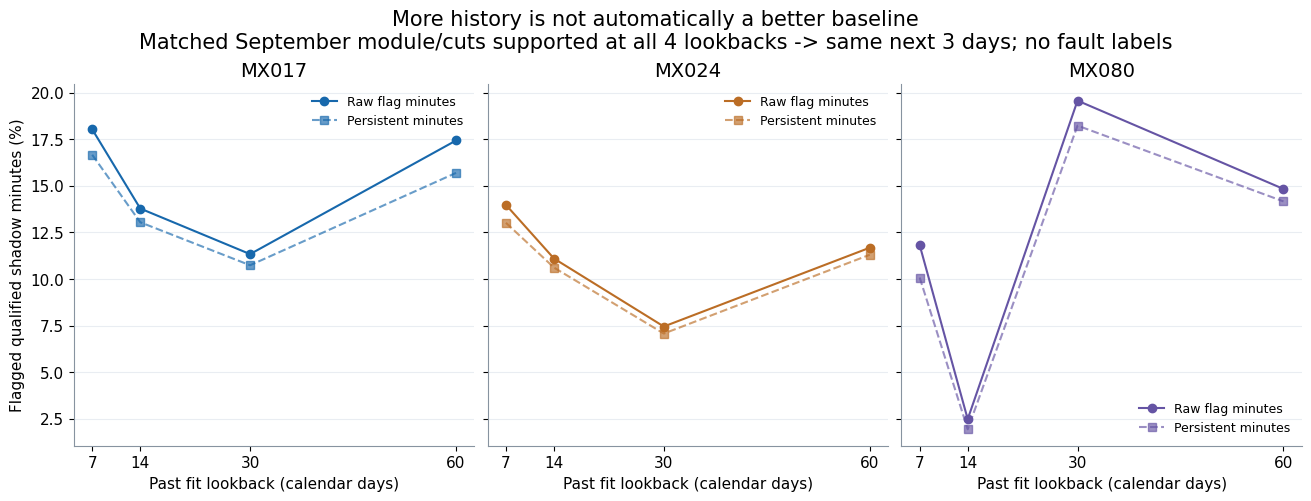

In [7]:
experiments=pd.read_csv(OUTPUT/'causal_shadow_experiments.csv',dtype={'machine':str},parse_dates=['cut'])
rates=experiments.groupby(['machine','fit_policy','lookback_days'])[['shadow_n','raw_flag_n','persistent_n','early_n','early_flag_n','late_n','late_flag_n']].sum()
rates['raw_flag_pct']=100*rates.raw_flag_n/rates.shadow_n
rates['early_flag_pct']=100*rates.early_flag_n/rates.early_n.replace(0,np.nan)
rates['late_flag_pct']=100*rates.late_flag_n/rates.late_n.replace(0,np.nan)
display(rates[['shadow_n','raw_flag_pct','early_n','early_flag_pct','late_n','late_flag_pct']].round(2))
fig=visuals.shadow_chart(OUTPUT); display(fig); plt.close(fig)


### 7. Guard against absorbing an abnormal plateau
กราฟ MX080/M6 7Sepเป็น regression case ที่เจ้าของยืนยันพฤติกรรมผิดปกติแล้ว. แยกการเปลี่ยนอุณหภูมิช่วงแรกออกจาก pressure plateauหลัง12:23. **Slopeต่ำอย่างเดียวไม่พอสำหรับ normal baseline** ต้องเทียบlevel/differentialกับpast referenceด้วย. ไม่อ้างว่าการเปลี่ยนValveเป็นสาเหตุเสียหรือมีการเติมน้ำยา

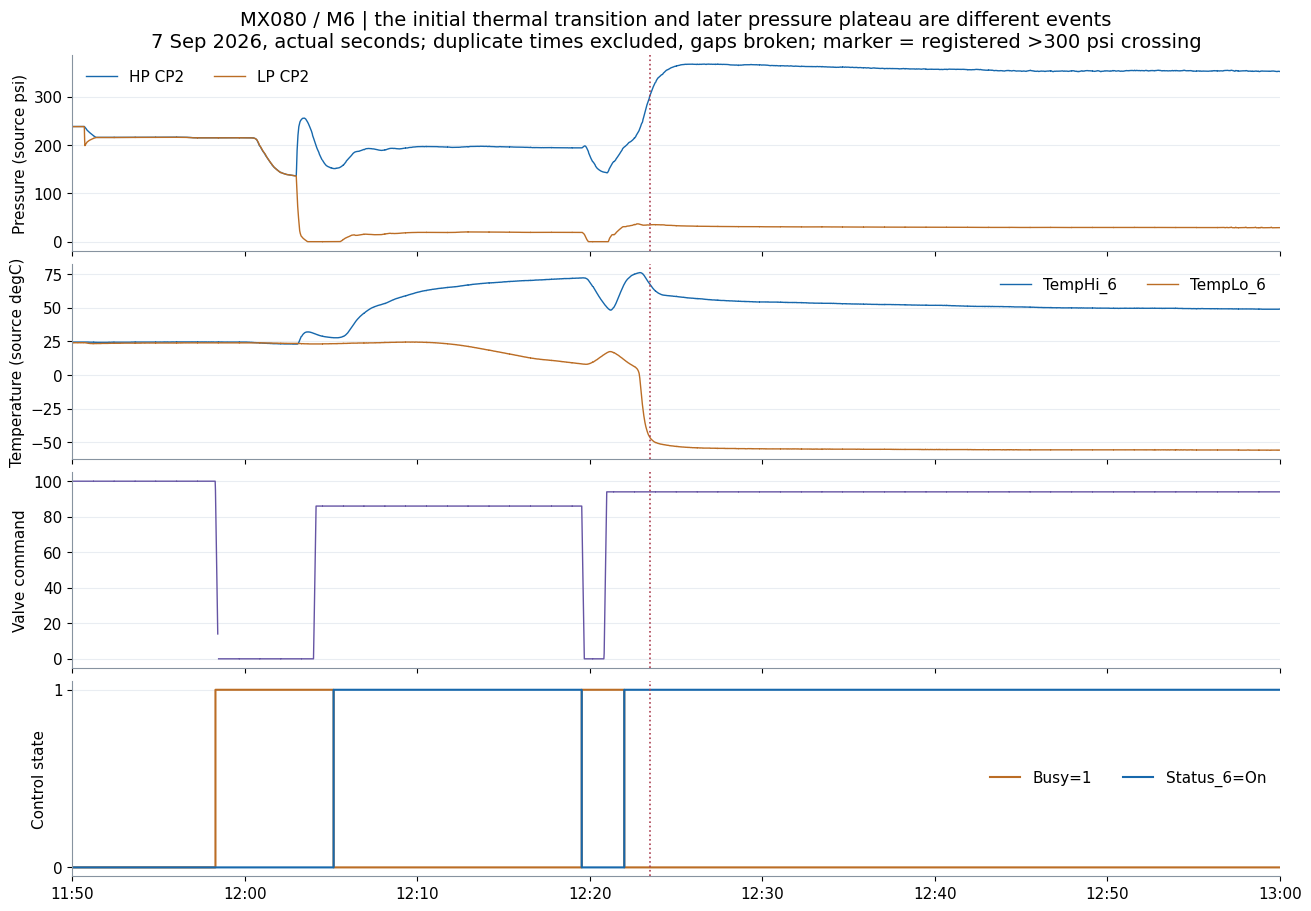

In [8]:
# Source parameter is passed explicitly; only this cell reopens one raw day for detailed verification.
fig=visuals.case_chart(OUTPUT, source_dir=SOURCE_DIR); display(fig); plt.close(fig)


### ข้อจำกัดของผล shadow ที่ต้องอ่านก่อนตัดสินใจ
การทดลอง1,059ชุดนี้ทำnumericalprofilefit/threshold/scoringส่วนเดียวกับcandidate แต่ **ไม่ได้สร้างCandidateในregistryหรือรันapproval lifecycleครบทุกgate**. ผล0flagไม่ใช่READY_FOR_APPROVAL: half-shift, quarantine, retainedcoverage, source/codebook/service/time prerequisitesและshadowreviewยังต้องตรวจแยก. Raw/persistentratesไม่ใช่falsepositiveหรือrecall เพราะไม่มีlabelsครบชุด

ผลไม่ได้บอกว่า14วันดีที่สุดทุกเครื่อง; ควรตรวจว่าประวัติแต่ละช่วงมีdistributionเดียวกันหรือไม่ก่อนเลือกlookback. 20minเป็นsensitivitysliceและเก็บได้เฉพาะonsetที่รู้ จึงไม่ใช้เป็นกฎตัดข้อมูลจริงจากผลนี้

## Takeaways
### 8. แนวทาง Auto-Calibration ที่ควรพัฒนาต่อ
1. คงlocal Machine×Module×qualified stateเป็นkeyหลัก; SVเป็นgate ไม่ใช่recipeชื่อเต็ม
2. เพิ่มphase/settling qualificationที่ใช้trailingข้อมูลเท่านั้น; เริ่มจาก slope+variation+control continuity และcompatiblelevel ไม่ใช้timer20minอย่างเดียว
3. ให้Historyยาวเป็น evidence bank แต่เลือกcandidateจากช่วงอดีตที่distributionคงที่; mixed-regimeให้REVIEW_REQUIRED ไม่เพิ่มscaleเพื่อให้ผ่าน
4. แยกmanual/state-change ledgerออกจากservice/refillที่ยืนยัน; shiftที่แบนแต่ต่างreferenceยังเก็บเป็นreview/episode
5. Candidateเก็บbaselineต่อวัน/cycle, uncertaintyและcoverageของบริบท ไม่ให้ millions ofsecondsแทนindependentcycles
6. Shadow3วันยังคงแยกqualified coverage, state availability, missing source, raw/persistentflagและcontributors; rejectต้องมีเหตุผลและเลือกช่วงอ้างอิงใหม่ ไม่retrythresholdจนผ่าน
7. ทดสอบknowncasesพร้อมfreshfuturestarts/steady periodsก่อนversioningและmanualapproval. รอบนี้ไม่มีActivepromotion

อายุ20minและlookbackที่เปรียบเทียบเป็นdiagnostic sensitivity **ยังไม่ใช่พารามิเตอร์ใหม่ที่อนุมัติ**. ไม่มีnormal/faultlabelsทั้งชุด จึงรายงานflag burdenแทนfalsepositive/recall.

### 9. QA และข้อจำกัด
ตรวจvectorizedwindowกับruntimebuilderทั้งnormal/duplicate/gap/manual/nonfinite/negativeValve/state และตรวจfitmedian/scale/q995กับexistingcandidate. Sourcehashและrowcountเก็บในmanifest. กราฟมีหน่วยและdenominator; staticexcluded. Sourceclock/unit/recipe/water/serviceไม่ครบ, trajectoriesตัดท้ายวัน/จำกัดstoredsample, age20subsetไม่แทนทั้งfleet. ไม่มีServer latency/restart/ActivequalificationclaimจากNotebookนี้

### References
- [NIST — Assessing Process Stability](https://www.itl.nist.gov/div898/handbook/ppc/section4/ppc45.htm): stabilityต้องพิจารณาdistribution/mean/varianceตามเวลา
- [NIST — Is the process stable?](https://www.itl.nist.gov/div898/handbook/pri/section2/pri22.htm): เทียบcontrol runsในrecipeที่ใกล้กัน
- [Zhang / NIST — Autocorrelated Data](https://www.nist.gov/publications/statistical-process-monitoring-autocorrelated-data): processsamplesไม่จำเป็นต้องindependent

แหล่งอ้างอิงสนับสนุนmethodology ไม่ได้กำหนด20min/lookback/floorsที่เหมาะสมเฉพาะHT9046MX